# Imports and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv("../data/raw/creditcard.csv")

# Dataset Preview

In [2]:
display(df.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Dataset Overview

In [3]:
print(f"Shape of dataframe: {df.shape}")
print(f"Number of missing values: {df.isnull().sum().sum()}")
print(f"Number of duplicate values: {df.duplicated().sum()}")
print("-" * 8, " Data types ", "-" * 8)
print(df.dtypes)

Shape of dataframe: (284807, 31)
Number of missing values: 0
Number of duplicate values: 1081
--------  Data types  --------
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


# Drop Duplicates

In [4]:
df = df.drop_duplicates()

# Class Distribution

In [5]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

# Feature Distribution Analysis

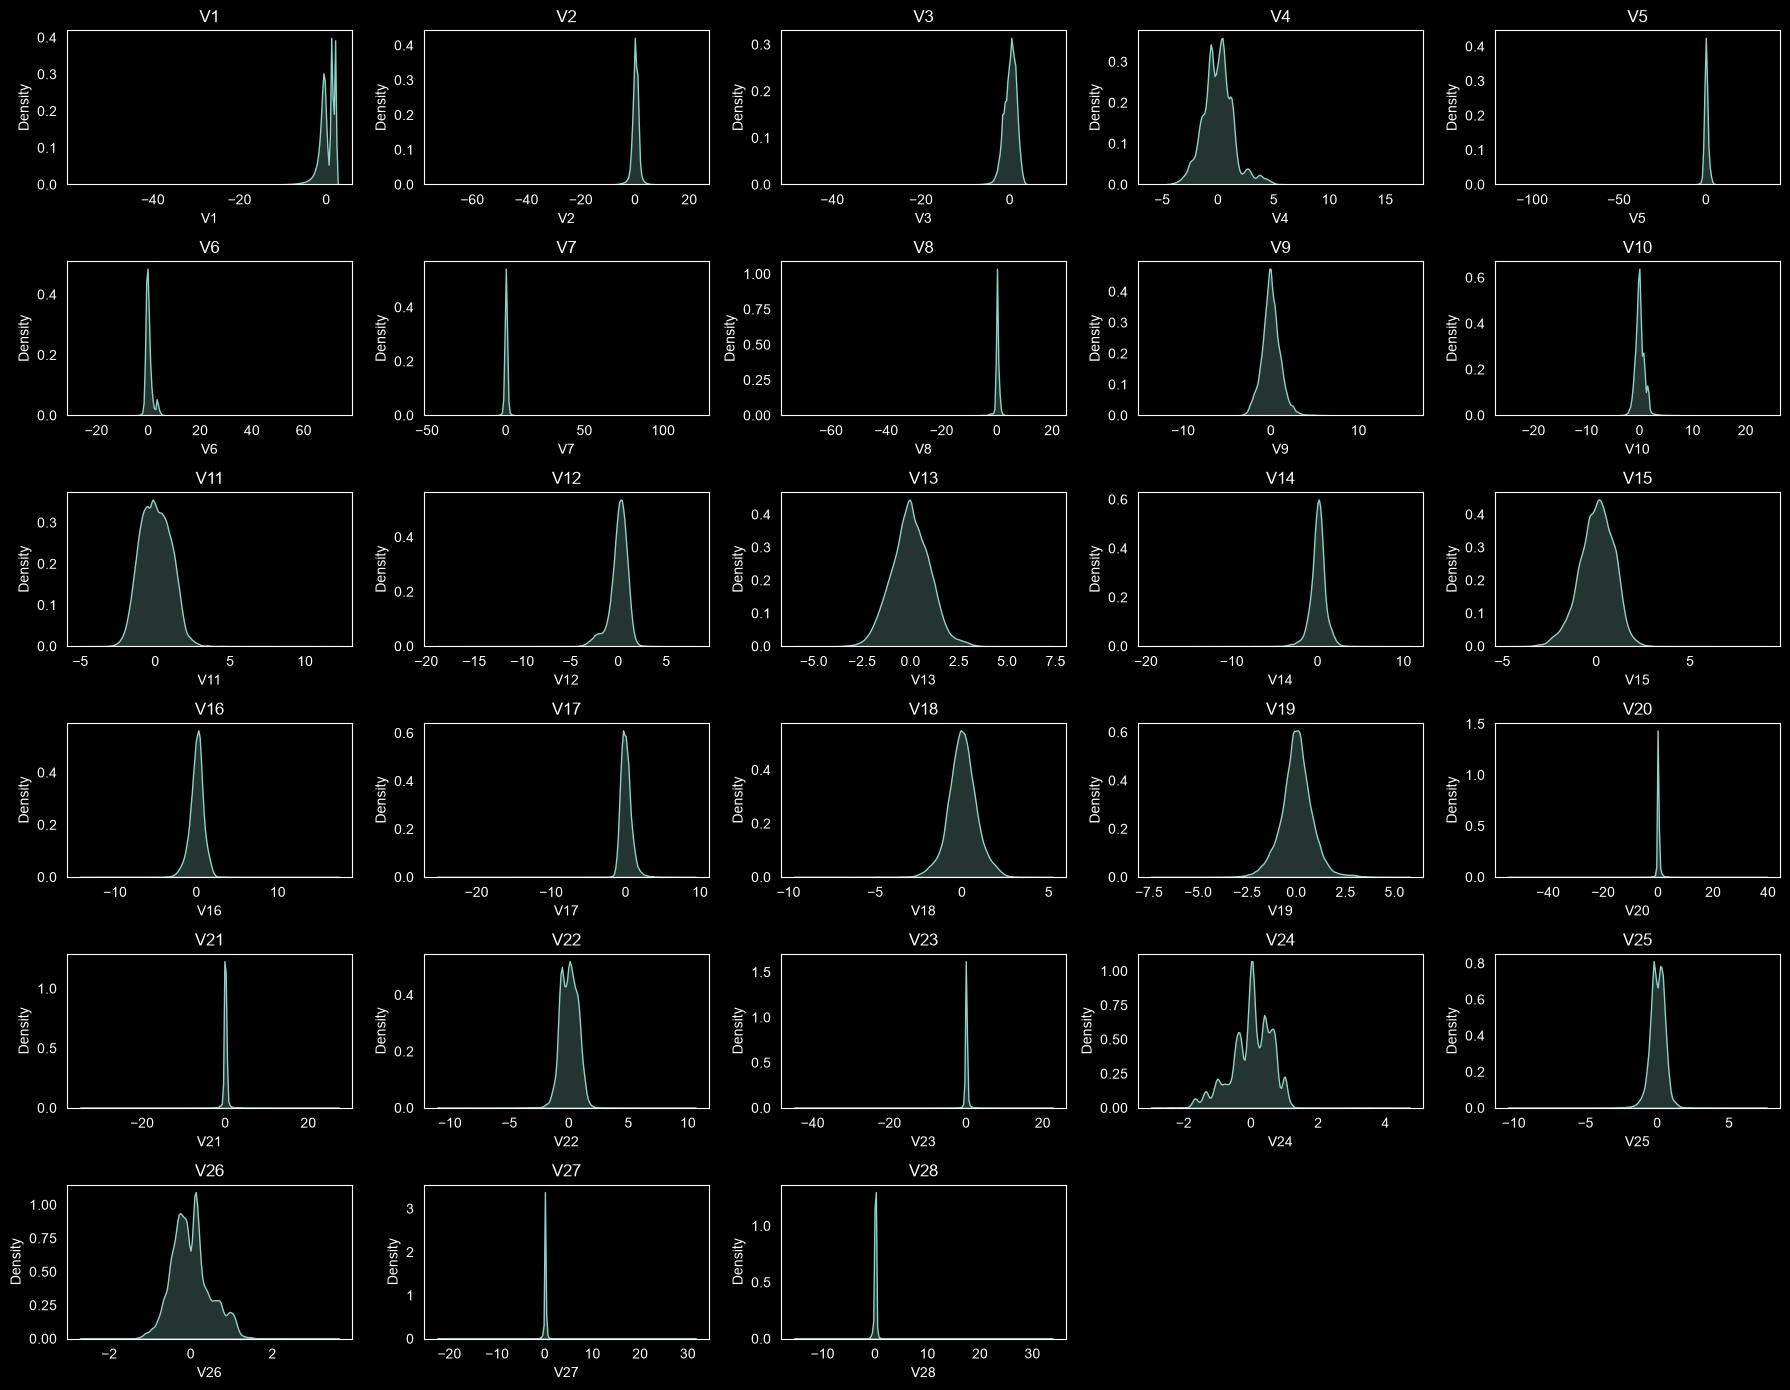

In [6]:
fig, axes = plt.subplots(6, 5, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate([f"V{i}" for i in range(1, 29)]):
    sns.kdeplot(data=df, x=col, ax=axes[i], fill=True)
    axes[i].set_title(col)
    axes[i].grid(False)

# Remove unused subplots
for i in range(28, 30):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Feature Correlation with Target

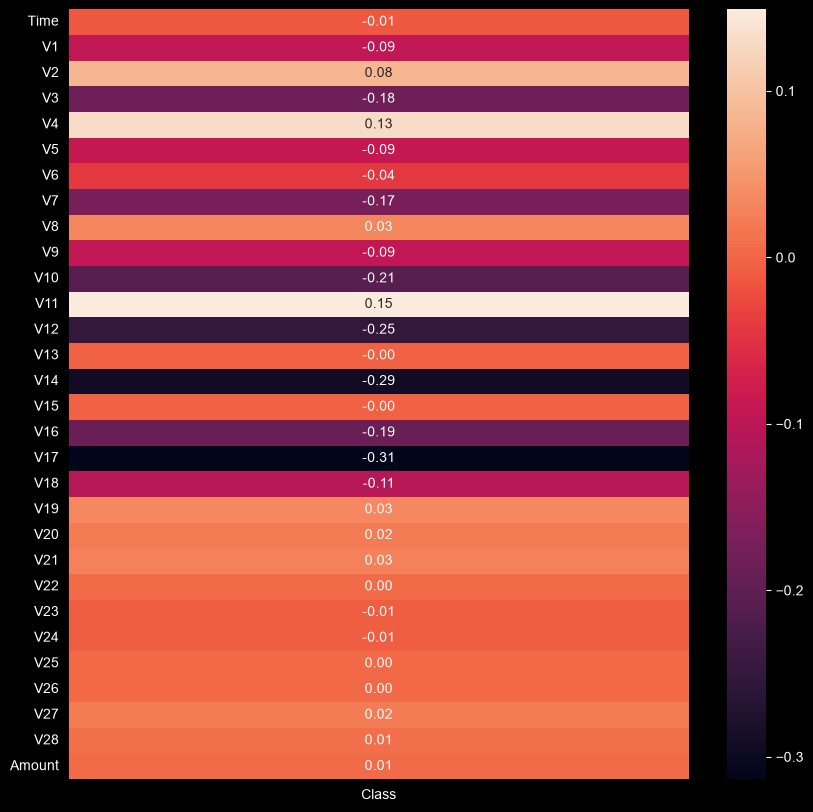

In [7]:
correlation = df.corr(method="pearson")[['Class']].drop('Class')

plt.figure(figsize=(10, 10))
sns.heatmap(correlation, annot=True, fmt=".2f")
plt.show()

# Feature Selection

- **DROP**: `Time`, `V6`, `V13`, `V20`, `V22`, `V23`, `V24`, `V25`, `V26`, `V27`, `V28`
- **KEEP**: `V2`, `V3`, `V4`, `V7`, `V9`, `V10`, `V11`, `V12`, `V14`, `V16`, `V17`, `V18`
- **TEST**: `V1`, `V5`, `V8`, `V19`, `V21`, `Amount`

## Function used

In [8]:
def check_outliers(column: str):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]
    non_outliers = df.drop(outliers.index)

    print(f"Number of outliers: {len(outliers)}")

    print("-" * 15, "Outliers", "-" * 15)
    print(outliers[column].head())

    print("-" * 15, "Outliers Relationship with Class", "-" * 15)
    print(outliers["Class"].value_counts(normalize=True))

    print("-" * 15, "Non Outliers Relationship with Class", "-" * 15)
    print(non_outliers["Class"].value_counts(normalize=True))

## V1

In [9]:
check_outliers("V1")

Number of outliers: 6948
--------------- Outliers ---------------
18    -5.401258
85    -4.575093
140   -5.101877
146   -5.285971
164   -6.093248
Name: V1, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.97726
1    0.02274
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998862
1    0.001138
Name: proportion, dtype: float64


## V2

In [10]:
check_outliers("V2")

Number of outliers: 13390
--------------- Outliers ---------------
18     -5.450148
85     -4.429184
89     -4.146007
146     4.847323
164   -12.114213
Name: V2, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.982823
1    0.017177
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999101
1    0.000899
Name: proportion, dtype: float64


## V3

In [11]:
check_outliers("V3")

Number of outliers: 3306
--------------- Outliers ---------------
164     -5.694973
958      4.017561
1632   -12.389545
4023     4.101716
5257    -4.075931
Name: V3, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.911373
1    0.088627
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999358
1    0.000642
Name: proportion, dtype: float64


## V4

In [12]:
check_outliers("V4")

Number of outliers: 11094
--------------- Outliers ---------------
51     3.710061
83    -4.515824
98     3.145414
116    3.481486
164    3.294389
Name: V4, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.972958
1    0.027042
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999365
1    0.000635
Name: proportion, dtype: float64


## V5

In [13]:
check_outliers("V5")

Number of outliers: 12221
--------------- Outliers ---------------
8     2.669599
11    2.924584
18    3.049106
24    2.941968
51   -6.631951
Name: V5, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.984371
1    0.015629
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998961
1    0.001039
Name: proportion, dtype: float64


## V6

In [14]:
check_outliers("V6")

Number of outliers: 22886
--------------- Outliers ---------------
8     3.721818
11    3.317027
24    2.955053
40    3.692977
51    5.122103
Name: V6, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.994538
1    0.005462
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998666
1    0.001334
Name: proportion, dtype: float64


## V7

In [15]:
check_outliers("V7")

Number of outliers: 8839
--------------- Outliers ---------------
51     4.371691
85    -2.705393
140    3.329603
150    3.315254
164    4.808426
Name: V7, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.967983
1    0.032017
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999309
1    0.000691
Name: proportion, dtype: float64


## V8

In [16]:
check_outliers("V8")

Number of outliers: 23904
--------------- Outliers ---------------
7    -3.807864
14   -1.907107
23   -1.617935
41    1.530817
51   -2.006868
Name: V8, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.990378
1    0.009622
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999065
1    0.000935
Name: proportion, dtype: float64


## V9

In [17]:
check_outliers("V9")

Number of outliers: 8199
--------------- Outliers ---------------
82     4.009259
146    3.558373
225    4.324752
290    3.580112
321   -2.517037
Name: V9, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.974509
1    0.025491
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999042
1    0.000958
Name: proportion, dtype: float64


## V10

In [18]:
check_outliers("V10")

Number of outliers: 9345
--------------- Outliers ---------------
82     6.051521
132    3.014355
146    6.427802
190    3.351079
225    6.286487
Name: V10, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.959337
1    0.040663
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999661
1    0.000339
Name: proportion, dtype: float64


## V11

In [19]:
check_outliers("V11")

Number of outliers: 735
--------------- Outliers ---------------
541     3.202033
1632    3.702177
2696    3.344171
2905    3.050256
4025    3.378338
Name: V11, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.62449
1    0.37551
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999304
1    0.000696
Name: proportion, dtype: float64


## V12

In [20]:
check_outliers("V12")

Number of outliers: 15282
--------------- Outliers ---------------
212     2.152055
460    -2.149863
472    -2.361050
541    -2.899907
1388   -1.981435
Name: V12, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.97448
1    0.02552
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999691
1    0.000309
Name: proportion, dtype: float64


## V13

In [21]:
check_outliers("V13")

Number of outliers: 3362
--------------- Outliers ---------------
343    -2.656601
1182    3.182541
1185    3.078366
1287   -2.847787
1401    3.099578
Name: V13, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.99762
1    0.00238
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998341
1    0.001659
Name: proportion, dtype: float64


## V14

In [22]:
check_outliers("V14")

Number of outliers: 14060
--------------- Outliers ---------------
82    -2.837136
102   -4.318378
104   -2.678081
108   -3.279054
146   -1.860653
Name: V14, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.970768
1    0.029232
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.99977
1    0.00023
Name: proportion, dtype: float64


## V15

In [23]:
check_outliers("V15")

Number of outliers: 2884
--------------- Outliers ---------------
180   -2.431499
218   -3.618060
238   -2.534978
306   -2.750145
370   -2.594957
Name: V15, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.996186
1    0.003814
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998355
1    0.001645
Name: proportion, dtype: float64


## V16

In [24]:
check_outliers("V16")

Number of outliers: 8180
--------------- Outliers ---------------
2     -2.890083
20    -2.044557
83    -2.811888
171   -2.444885
172   -2.627095
Name: V16, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.959291
1    0.040709
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999492
1    0.000508
Name: proportion, dtype: float64


## V17

In [25]:
check_outliers("V17")

Number of outliers: 7353
--------------- Outliers ---------------
82    -1.942303
102    2.729168
108    2.698337
119    1.780961
134    1.915146
Name: V17, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.948456
1    0.051544
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.99966
1    0.00034
Name: proportion, dtype: float64


## V18

In [26]:
check_outliers("V18")

Number of outliers: 7468
--------------- Outliers ---------------
38    -2.830035
68    -2.119314
96    -2.514235
112   -2.449500
119   -2.120498
Name: V18, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.970675
1    0.029325
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999081
1    0.000919
Name: proportion, dtype: float64


## V19

In [27]:
check_outliers("V19")

Number of outliers: 10150
--------------- Outliers ---------------
2    -2.261857
14    2.221868
21   -2.027612
23    2.177807
69    1.890364
Name: V19, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.987094
1    0.012906
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.99875
1    0.00125
Name: proportion, dtype: float64


## V20

In [28]:
check_outliers("V20")

Number of outliers: 27553
--------------- Outliers ---------------
14   -1.582122
18   -2.196848
74    0.667847
82    2.456724
83   -0.769854
Name: V20, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.993467
1    0.006533
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998856
1    0.001144
Name: proportion, dtype: float64


## V21

In [29]:
check_outliers("V21")

Number of outliers: 14401
--------------- Outliers ---------------
7     1.943465
14    1.151663
23    1.650180
51    1.393406
82   -0.852309
Name: V21, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.984307
1    0.015693
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999083
1    0.000917
Name: proportion, dtype: float64


## V22

In [30]:
check_outliers("V22")

Number of outliers: 1298
--------------- Outliers ---------------
160    -2.776923
164    -2.264037
417    -2.331390
2061   -2.491575
2114   -3.138177
Name: V22, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.984592
1    0.015408
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998396
1    0.001604
Name: proportion, dtype: float64


## V23

In [31]:
check_outliers("V23")

Number of outliers: 18467
--------------- Outliers ---------------
2     0.909412
14    1.020586
18    2.458589
24    0.870300
25    0.742435
Name: V23, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.992581
1    0.007419
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998733
1    0.001267
Name: proportion, dtype: float64


## V24

In [32]:
check_outliers("V24")

Number of outliers: 4758
--------------- Outliers ---------------
183   -1.688158
218   -1.735297
220   -1.724222
222   -1.724175
280   -1.686137
Name: V24, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.999369
1    0.000631
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998315
1    0.001685
Name: proportion, dtype: float64


## V25

In [33]:
check_outliers("V25")

Number of outliers: 5333
--------------- Outliers ---------------
244    -1.389079
718    -1.357580
787    -1.544209
1329   -1.577384
1515    1.629684
Name: V25, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.989687
1    0.010313
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998499
1    0.001501
Name: proportion, dtype: float64


## V26

In [34]:
check_outliers("V26")

Number of outliers: 5665
--------------- Outliers ---------------
40    1.196549
48    1.194928
61    1.141241
69    3.065576
83   -1.243924
Name: V26, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.998588
1    0.001412
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998328
1    0.001672
Name: proportion, dtype: float64


## V27

In [35]:
check_outliers("V27")

Number of outliers: 38799
--------------- Outliers ---------------
7    -1.206921
18    0.392053
23    0.336634
24    0.707519
25    0.359969
Name: V27, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.991572
1    0.008428
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999404
1    0.000596
Name: proportion, dtype: float64


## V28

In [36]:
check_outliers("V28")

Number of outliers: 30094
--------------- Outliers ---------------
7    -1.085339
18    0.949594
64    0.316910
66   -0.473218
67   -0.272463
Name: V28, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.99156
1    0.00844
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.999137
1    0.000863
Name: proportion, dtype: float64


## Amount

In [37]:
check_outliers("Amount")

Number of outliers: 31685
--------------- Outliers ---------------
2      378.66
20     231.71
51    1402.95
64     243.66
85     200.01
Name: Amount, dtype: float64
--------------- Outliers Relationship with Class ---------------
Class
0    0.997254
1    0.002746
Name: proportion, dtype: float64
--------------- Non Outliers Relationship with Class ---------------
Class
0    0.998469
1    0.001531
Name: proportion, dtype: float64


# Save Preprocessed Dataset

In [38]:
df.to_csv("../data/preprocessed/creditcard.csv")